<a href="https://colab.research.google.com/github/kata2009/CSN_2026/blob/main/Simulacio%CC%81n_del_Examen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRIMERAS 10 FILAS


,user_id,app_version,platform,session_duration,number_of_sessions,country,user_feedback
0,1,1.2,Android,109,11,France,1
1,2,1.3,Android,116,17,UK,2
2,3,1.0,Android,94,13,France,5
3,4,1.2,iOS,47,1,Canada,4
4,5,1.2,iOS,99,2,Canada,3
5,6,1.3,Android,55,9,Germany,4
6,7,1.0,iOS,168,3,Mexico,2
7,8,1.0,iOS,52,1,Canada,4
8,9,1.2,iOS,144,16,USA,1
9,10,1.1,iOS,13,6,France,2



INFORMACIÓN ORIGINAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   user_id             300 non-null    string
 1   app_version         300 non-null    string
 2   platform            300 non-null    string
 3   session_duration    300 non-null    int64 
 4   number_of_sessions  300 non-null    int64 
 5   country             300 non-null    string
 6   user_feedback       300 non-null    int64 
dtypes: int64(3), string(4)
memory usage: 16.5 KB

ESTADÍSTICAS ORIGINALES


,session_duration,number_of_sessions,user_feedback
count,300.000000,300.000000,300.000000
mean,95.840000,9.596667,2.926667
std,51.922773,5.672853,1.449699
min,1.000000,1.000000,1.000000
25%,51.250000,5.000000,2.000000
50%,100.500000,9.000000,3.000000
75%,141.250000,15.000000,4.000000
max,179.000000,19.000000,5.000000



PLATAFORMAS ORIGINALES
platform
iOS        163
Android    137
Name: count, dtype: Int64

PAÍSES ORIGINALES
country
Spain      45
Mexico     39
France     37
Germany    37
Italy      36
UK         36
Canada     35
USA        35
Name: count, dtype: Int64

VALORES FALTANTES TRAS CONVERTIR LOS DATOS
user_id               0
app_version           0
platform              0
session_duration      0
number_of_sessions    0
country               0
user_feedback         0
dtype: int64

Filas completamente duplicadas eliminadas: 0
Filas con identificadores en conflicto apartadas: 0

VALORES INAPROPIADOS
Duraciones inválidas: 0
Cantidades de sesiones inválidas: 0
Puntuaciones inválidas: 0

Filas eliminadas por datos esenciales faltantes: 0

MÉTODOS UTILIZADOS PARA LOS FALTANTES
- Identificador o uso faltante: eliminación, para no inventar registros.
- Categorías faltantes: etiqueta 'Sin información'.
- Feedback faltante: se conserva y se excluye de los cálculos de puntuación.

TIPOS DE DATOS FINALE

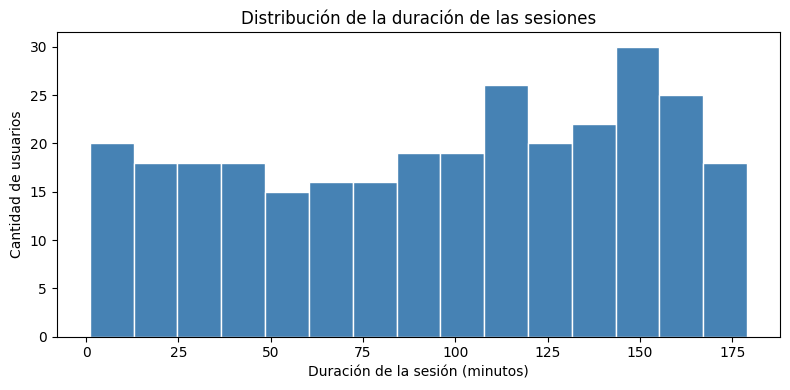


INTERPRETACIÓN DEL HISTOGRAMA
La duración mediana es 100.5 minutos.
Las duraciones van de 1.0 a 179.0 minutos.
El histograma muestra en qué intervalos se concentran las sesiones.


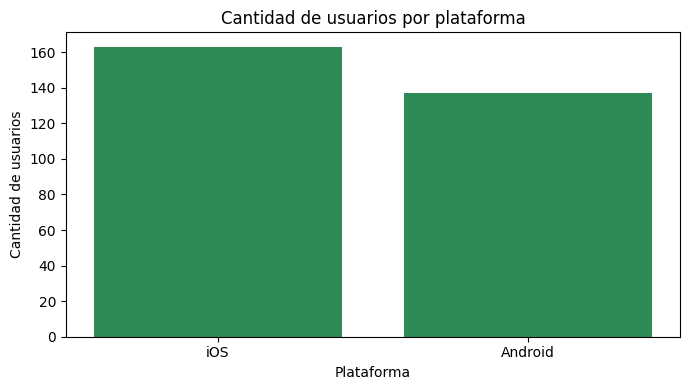


INTERPRETACIÓN DEL GRÁFICO DE BARRAS
Categoría o categorías más frecuentes: iOS
Cada una tiene 163 usuarios en los datos analizados.
La frecuencia indica presencia en la muestra, no satisfacción ni retención.


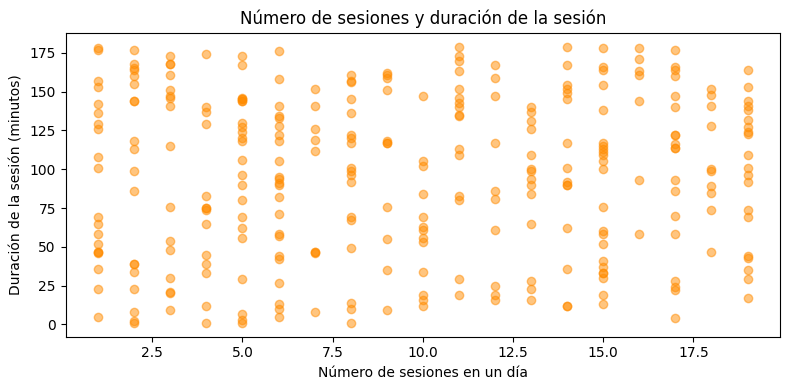


INTERPRETACIÓN DEL GRÁFICO DE DISPERSIÓN
Correlación lineal de Pearson: 0.06.
Un valor cercano a 0 indica poca relación lineal; cercano a 1 o -1 indica una relación lineal más marcada.
Una asociación entre las variables no demuestra una relación de causa y efecto.

INTERPRETACIÓN DEL DIAGRAMA DE CAJAS


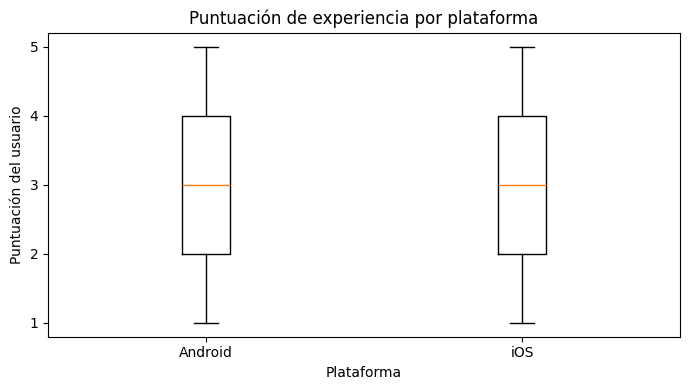

,count,mean,median
platform,,,
Android,137,2.91,3.0
iOS,163,2.94,3.0


La línea dentro de cada caja representa la mediana.
La caja muestra el 50 % central de las puntuaciones.
Como las puntuaciones solo van de 1 a 5, puede haber muchos empates.
Las diferencias observadas no prueban que una plataforma sea mejor.

CONCLUSIONES
Se revisaron duplicados, faltantes, categorías, tipos y valores inválidos.
Se exploraron duración, plataforma, frecuencia de uso y experiencia.
Los datos fueron generados al azar y sirven para practicar.
No podemos medir retención con este archivo: necesitamos observar a los mismos usuarios en distintas fechas.

ARCHIVOS DISPONIBLES EN EL PANEL DE COLAB
- user_app_data.csv: datos originales.
- user_app_data_limpio.csv: datos preparados para el análisis.
- usuarios_para_revision.csv: identificadores en conflicto, si los hubo.


In [6]:
# Las interpretaciones se calculan a partir de los resultados.
# Estos datos sintéticos no permiten sacar conclusiones sobre usuarios reales.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. GENERAR LOS DATOS

np.random.seed(42)

data = pd.DataFrame({
    "user_id": range(1, 301),
    "app_version": np.random.choice(["1.0", "1.1", "1.2", "1.3"], 300),
    "platform": np.random.choice(["Android", "iOS"], 300),
    "session_duration": np.random.randint(1, 180, 300),
    "number_of_sessions": np.random.randint(1, 20, 300),
    "country": np.random.choice(
        ["USA", "Canada", "Mexico", "UK", "Germany", "France", "Spain", "Italy"],
        300
    ),
    "user_feedback": np.random.randint(1, 6, 300)
})

data.to_csv("user_app_data.csv", index=False)

# Leer identificadores y versiones como texto.
# Una versión como 1.0 es una etiqueta, no un número para hacer cálculos.
datos = pd.read_csv(
    "user_app_data.csv",
    dtype={
        "user_id": "string",
        "app_version": "string",
        "platform": "string",
        "country": "string"
    }
)

print("PRIMERAS 10 FILAS")
display(datos.head(10))

print("\nINFORMACIÓN ORIGINAL")
datos.info()

print("\nESTADÍSTICAS ORIGINALES")
display(datos.describe())

filas_originales = len(datos)

# 2. CORREGIR TEXTOS Y CATEGORÍAS

print("\nPLATAFORMAS ORIGINALES")
print(datos["platform"].value_counts(dropna=False))

print("\nPAÍSES ORIGINALES")
print(datos["country"].value_counts(dropna=False))

columnas_texto = ["user_id", "app_version", "platform", "country"]

for columna in columnas_texto:
    datos[columna] = datos[columna].astype("string").str.strip()
    datos[columna] = datos[columna].replace("", pd.NA)

# Convertir variantes como android, Android y ANDROID.
plataformas = {
    "android": "Android",
    "ios": "iOS"
}

datos["platform"] = datos["platform"].str.lower().map(plataformas)

# Uniformar variantes frecuentes de los países del generador.
paises = {
    "usa": "USA",
    "us": "USA",
    "united states": "USA",
    "estados unidos": "USA",
    "canada": "Canada",
    "canadá": "Canada",
    "mexico": "Mexico",
    "méxico": "Mexico",
    "uk": "UK",
    "united kingdom": "UK",
    "reino unido": "UK",
    "germany": "Germany",
    "alemania": "Germany",
    "france": "France",
    "francia": "France",
    "spain": "Spain",
    "españa": "Spain",
    "italy": "Italy",
    "italia": "Italy"
}

# Un país no reconocido se conserva: podría ser otro país válido.
paises_limpios = datos["country"].str.lower().map(paises)
datos["country"] = paises_limpios.fillna(datos["country"])

# No restringimos las versiones a las cuatro del generador:
# podrían existir otras versiones válidas.


# 3. CORREGIR TIPOS NUMÉRICOS

columnas_numericas = [
    "session_duration",
    "number_of_sessions",
    "user_feedback"
]

for columna in columnas_numericas:
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")
    datos[columna] = datos[columna].replace(
        [np.inf, -np.inf],
        np.nan
    )

print("\nVALORES FALTANTES TRAS CONVERTIR LOS DATOS")
print(datos.isna().sum())

# 4. IDENTIFICAR Y ABORDAR DUPLICADOS

# Después de limpiar los textos, detectar filas idénticas.
duplicados = datos.duplicated().sum()
datos = datos.drop_duplicates().copy()

print("\nFilas completamente duplicadas eliminadas:", duplicados)

# El diccionario indica que user_id es único.
# Si quedan registros distintos del mismo usuario, no sabemos cuál es correcto.
# Los apartamos para revisión en lugar de elegir uno arbitrariamente.
usuarios_repetidos = (
    datos["user_id"].notna()
    & datos["user_id"].duplicated(keep=False)
)

conflictos = datos.loc[usuarios_repetidos].copy()
conflictos.to_csv("usuarios_para_revision.csv", index=False)

datos = datos.loc[~usuarios_repetidos].copy()

print("Filas con identificadores en conflicto apartadas:", len(conflictos))

# 5. IDENTIFICAR VALORES INAPROPIADOS

# Suponemos que cada sesión registrada ocurre dentro de un día.
# Una sesión no puede durar más de 1440 minutos (24 horas).
# No eliminamos valores altos solo por ser poco frecuentes.
duracion_invalida = (
    (datos["session_duration"] < 0)
    | (datos["session_duration"] > 1440)
)

# Las sesiones deben ser cantidades enteras no negativas.
sesiones_invalidas = (
    (datos["number_of_sessions"] < 0)
    | (datos["number_of_sessions"] % 1 != 0)
)

# La puntuación debe ser un entero entre 1 y 5.
feedback_invalido = (
    (datos["user_feedback"] < 1)
    | (datos["user_feedback"] > 5)
    | (datos["user_feedback"] % 1 != 0)
)

print("\nVALORES INAPROPIADOS")
print("Duraciones inválidas:", duracion_invalida.sum())
print("Cantidades de sesiones inválidas:", sesiones_invalidas.sum())
print("Puntuaciones inválidas:", feedback_invalido.sum())

# Convertir los valores inválidos en faltantes antes de tratarlos.
datos.loc[duracion_invalida, "session_duration"] = np.nan
datos.loc[sesiones_invalidas, "number_of_sessions"] = np.nan
datos.loc[feedback_invalido, "user_feedback"] = np.nan

# No multiplicamos duración por número de sesiones:
# el diccionario no aclara si la duración es un promedio diario
# ni si corresponde a todas las sesiones de ese día.


# 6. TRATAR LOS VALORES FALTANTES

# Sin identificador no podemos distinguir al usuario.
# Sin duración o número de sesiones no podemos analizar su uso.
# Eliminamos esas filas para no inventar comportamientos.
columnas_esenciales = [
    "user_id",
    "session_duration",
    "number_of_sessions"
]

filas_antes = len(datos)
datos = datos.dropna(subset=columnas_esenciales).copy()

print(
    "\nFilas eliminadas por datos esenciales faltantes:",
    filas_antes - len(datos)
)

if datos.empty:
    raise ValueError("No quedaron registros válidos para analizar.")

# En las categorías usamos una etiqueta explícita.
# No usamos la moda porque asignaría una categoría sin evidencia.
for columna in ["platform", "country", "app_version"]:
    datos[columna] = datos[columna].fillna("Sin información")

# Conservamos las puntuaciones faltantes.
# No responder una encuesta no equivale a puntuar 0 ni a dar la media.
# Los promedios y gráficos de feedback usarán solo respuestas válidas.

print("\nMÉTODOS UTILIZADOS PARA LOS FALTANTES")
print("- Identificador o uso faltante: eliminación, para no inventar registros.")
print("- Categorías faltantes: etiqueta 'Sin información'.")
print("- Feedback faltante: se conserva y se excluye de los cálculos de puntuación.")

# 7. DEFINIR LOS TIPOS FINALES

datos["user_id"] = datos["user_id"].astype("string")
datos["app_version"] = datos["app_version"].astype("string")
datos["platform"] = datos["platform"].astype("category")
datos["country"] = datos["country"].astype("category")
datos["session_duration"] = datos["session_duration"].astype(float)
datos["number_of_sessions"] = datos["number_of_sessions"].astype("Int64")
datos["user_feedback"] = datos["user_feedback"].astype("Int64")

datos = datos.reset_index(drop=True)

print("\nTIPOS DE DATOS FINALES")
print(datos.dtypes)

print("\nRESUMEN DE LIMPIEZA")
print("Filas originales:", filas_originales)
print("Filas disponibles:", len(datos))
print("Identificadores únicos:", datos["user_id"].nunique())

print("\nVALORES FALTANTES FINALES")
print(datos.isna().sum())

# 8. VISUALIZACIÓN UNIVARIANTE: HISTOGRAMA

# Un histograma permite observar cómo se distribuye una variable numérica.
plt.figure(figsize=(8, 4))
plt.hist(
    datos["session_duration"],
    bins=15,
    color="steelblue",
    edgecolor="white"
)
plt.title("Distribución de la duración de las sesiones")
plt.xlabel("Duración de la sesión (minutos)")
plt.ylabel("Cantidad de usuarios")
plt.tight_layout()
plt.show()

# Interpretación calculada a partir de los datos.
print("\nINTERPRETACIÓN DEL HISTOGRAMA")
print(
    f"La duración mediana es "
    f"{datos['session_duration'].median():.1f} minutos."
)
print(
    f"Las duraciones van de {datos['session_duration'].min():.1f} "
    f"a {datos['session_duration'].max():.1f} minutos."
)
print("El histograma muestra en qué intervalos se concentran las sesiones.")

# 9. VISUALIZACIÓN UNIVARIANTE: BARRAS

# Un gráfico de barras permite comparar frecuencias de categorías.
conteo_plataformas = datos["platform"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(
    conteo_plataformas.index.astype(str),
    conteo_plataformas.values,
    color="seagreen"
)
plt.title("Cantidad de usuarios por plataforma")
plt.xlabel("Plataforma")
plt.ylabel("Cantidad de usuarios")
plt.tight_layout()
plt.show()

print("\nINTERPRETACIÓN DEL GRÁFICO DE BARRAS")

mayor_frecuencia = conteo_plataformas.max()
plataformas_mayores = conteo_plataformas[
    conteo_plataformas == mayor_frecuencia
].index.astype(str).tolist()

print(
    "Categoría o categorías más frecuentes:",
    ", ".join(plataformas_mayores)
)
print(f"Cada una tiene {mayor_frecuencia} usuarios en los datos analizados.")
print("La frecuencia indica presencia en la muestra, no satisfacción ni retención.")

# 10. VISUALIZACIÓN MULTIVARIANTE: DISPERSIÓN

# Comparar dos variables numéricas:
# número de sesiones y duración de la sesión.
plt.figure(figsize=(8, 4))
plt.scatter(
    datos["number_of_sessions"].astype(float),
    datos["session_duration"],
    alpha=0.5,
    color="darkorange"
)
plt.title("Número de sesiones y duración de la sesión")
plt.xlabel("Número de sesiones en un día")
plt.ylabel("Duración de la sesión (minutos)")
plt.tight_layout()
plt.show()

correlacion = datos["number_of_sessions"].astype(float).corr(
    datos["session_duration"]
)

print("\nINTERPRETACIÓN DEL GRÁFICO DE DISPERSIÓN")

if pd.isna(correlacion):
    print("No se puede calcular la correlación: falta variación o suficientes datos.")
else:
    print(f"Correlación lineal de Pearson: {correlacion:.2f}.")
    print(
        "Un valor cercano a 0 indica poca relación lineal; "
        "cercano a 1 o -1 indica una relación lineal más marcada."
    )

print("Una asociación entre las variables no demuestra una relación de causa y efecto.")

# 11. VISUALIZACIÓN MULTIVARIANTE: DIAGRAMA DE CAJAS

# Comparar la distribución del feedback entre plataformas.
# Excluir puntuaciones faltantes y plataformas sin identificar.
datos_feedback = datos.dropna(subset=["user_feedback"]).copy()
datos_feedback = datos_feedback[
    datos_feedback["platform"].isin(["Android", "iOS"])
]

print("\nINTERPRETACIÓN DEL DIAGRAMA DE CAJAS")

if datos_feedback.empty:
    print("No hay puntuaciones válidas con plataforma conocida para comparar.")
else:
    plataformas = [
        plataforma
        for plataforma in ["Android", "iOS"]
        if (datos_feedback["platform"] == plataforma).any()
    ]

    grupos = [
        datos_feedback.loc[
            datos_feedback["platform"] == plataforma,
            "user_feedback"
        ].astype(float).to_numpy()
        for plataforma in plataformas
    ]

    plt.figure(figsize=(7, 4))
    plt.boxplot(grupos)
    plt.xticks(range(1, len(plataformas) + 1), plataformas)
    plt.title("Puntuación de experiencia por plataforma")
    plt.xlabel("Plataforma")
    plt.ylabel("Puntuación del usuario")
    plt.yticks([1, 2, 3, 4, 5])
    plt.tight_layout()
    plt.show()

    resumen_feedback = datos_feedback.groupby(
        "platform",
        observed=True
    )["user_feedback"].agg(["count", "mean", "median"])

    display(resumen_feedback.round(2))

    print("La línea dentro de cada caja representa la mediana.")
    print("La caja muestra el 50 % central de las puntuaciones.")
    print("Como las puntuaciones solo van de 1 a 5, puede haber muchos empates.")
    print("Las diferencias observadas no prueban que una plataforma sea mejor.")

# 12. CONCLUSIONES Y LIMITACIONES

print("\nCONCLUSIONES")
print("Se revisaron duplicados, faltantes, categorías, tipos y valores inválidos.")
print("Se exploraron duración, plataforma, frecuencia de uso y experiencia.")
print("Los datos fueron generados al azar y sirven para practicar.")
print(
    "No podemos medir retención con este archivo: "
    "necesitamos observar a los mismos usuarios en distintas fechas."
)

# 13. GUARDAR LOS DATOS LIMPIOS

datos.to_csv("user_app_data_limpio.csv", index=False)

print("\nARCHIVOS DISPONIBLES EN EL PANEL DE COLAB")
print("- user_app_data.csv: datos originales.")
print("- user_app_data_limpio.csv: datos preparados para el análisis.")
print("- usuarios_para_revision.csv: identificadores en conflicto, si los hubo.")